In [2]:
import warnings
import logging
import pyodbc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

INITIAL_TRAIN_WEEKS = 52
HORIZON_WEEKS = 2
EXCLUDE_LAST_WEEK = True
SEASONAL_PERIOD = 4  # Four-week cycle to test, NOT calendar-month seasonality.

logging.getLogger('cmdstanpy').setLevel(logging.WARNING)

## 1. Read weekly sales by region from SQL

In [3]:
conn = pyodbc.connect(
    'DRIVER={ODBC Driver 18 for SQL Server};'
    r'SERVER=localhost\MSSQLSERVER01;'
    'DATABASE=Proyecto_Final_MD;'
    'Trusted_Connection=yes;Encrypt=yes;TrustServerCertificate=yes;',
    timeout=10,
)
try:
    cursor = conn.cursor()
    cursor.execute('''
        SELECT region, purchase_year, purchase_week,
               SUM(CAST(price AS decimal(19,2))) AS sales
        FROM gold.dim_demand
        GROUP BY region, purchase_year, purchase_week
        ORDER BY region, purchase_year, purchase_week
    ''')
    df = pd.DataFrame.from_records(
        [tuple(row) for row in cursor.fetchall()],
        columns=[column[0] for column in cursor.description],
    )
finally:
    conn.close()

## 2. Prepare the timeline
The existing gold table has year/week labels rather than original dates. We retain the project's ISO-date approximation; calendar-year / ISO-week mismatches at New Year remain a source-data limitation. Missing weeks are treated as zero recorded sales. The final recorded week is excluded by default because it may be incomplete.

In [4]:
df['week_start'] = pd.to_datetime(
    df.purchase_year.astype(int).astype(str) + '-W'
    + df.purchase_week.astype(int).astype(str).str.zfill(2) + '-1',
    format='%G-W%V-%u',
)
df['sales'] = df.sales.astype(float)
if df.empty or not np.isfinite(df.sales).all() or df.sales.lt(0).any():
    raise ValueError('Expected nonempty, finite, nonnegative sales.')
if df.region.isna().any() or df.region.astype(str).str.strip().eq('').any():
    raise ValueError('Missing region labels.')
if df.duplicated(['region', 'week_start']).any():
    raise ValueError('Duplicate region/week labels: inspect source dates.')
calendar = pd.date_range(df.week_start.min(), df.week_start.max(), freq='W-MON')
if EXCLUDE_LAST_WEEK:
    calendar = calendar[:-1]
regional_sales = df.pivot(index='week_start', columns='region', values='sales').reindex(calendar).fillna(0)
if not isinstance(INITIAL_TRAIN_WEEKS, int) or not 12 <= INITIAL_TRAIN_WEEKS < len(calendar):
    raise ValueError('Initial training must leave test weeks and contain at least 12 weeks.')
if not isinstance(HORIZON_WEEKS, int) or HORIZON_WEEKS < 1:
    raise ValueError('Horizon must be a positive integer.')
if not isinstance(SEASONAL_PERIOD, int) or not 2 <= SEASONAL_PERIOD <= INITIAL_TRAIN_WEEKS // 2:
    raise ValueError('Seasonal period must fit at least two cycles in initial training.')
print(f'Eligible history: {calendar.min().date()} to {calendar.max().date()} ({len(calendar)} weeks)')
print(f'Initial training: {INITIAL_TRAIN_WEEKS} weeks; forecast block: {HORIZON_WEEKS} weeks')
print(f'Evaluation: {calendar[INITIAL_TRAIN_WEEKS].date()} to {calendar[-1].date()}')
print('Regions:', ', '.join(regional_sales.columns))

Eligible history: 2016-09-12 to 2018-08-20 (102 weeks)
Initial training: 52 weeks; forecast block: 2 weeks
Evaluation: 2017-09-11 to 2018-08-20
Regions: Centro-Oeste, Nordeste, Norte, Sudeste, Sul


## 3. Naive and Random Forest
RF uses past-sales lags, rolling averages and month. Within each forecast block it uses its own predictions, never the test actuals.

In [5]:
def forecast_naive(train, future_dates):
    return np.repeat(train.iloc[-1], len(future_dates))


def forecast_rf(train, future_dates):
    table = train.to_frame(name='sales')
    table['month'] = table.index.month
    for lag in range(1, 5):
        table[f'lag_{lag}'] = table.sales.shift(lag)
    table['mean_4'] = table.sales.shift(1).rolling(4).mean()
    table['mean_8'] = table.sales.shift(1).rolling(8).mean()
    table = table.dropna()
    features = ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'mean_4', 'mean_8', 'month']
    model = RandomForestRegressor(
        n_estimators=300, max_depth=4, min_samples_leaf=3,
        random_state=42, n_jobs=-1,
    )
    model.fit(table[features], table.sales)
    history = train.tolist()
    predictions = []
    for week in future_dates:
        inputs = pd.DataFrame([{
            'lag_1': history[-1], 'lag_2': history[-2],
            'lag_3': history[-3], 'lag_4': history[-4],
            'mean_4': np.mean(history[-4:]), 'mean_8': np.mean(history[-8:]),
            'month': week.month,
        }])
        prediction = float(model.predict(inputs[features])[0])
        predictions.append(prediction)
        history.append(prediction)  # Not the held-out actual sales!
    return np.array(predictions)

## 4. ARIMAX and SARIMAX
Both use month sine/cosine inputs. SARIMAX additionally tests a four-week seasonal AR term. This is a candidate cycle, not an established pattern. Failed/nonconverged fits are recorded rather than replaced by another model.

In [6]:
def month_inputs(dates):
    return pd.DataFrame({
        'month_sin': np.sin(2 * np.pi * (dates.month - 1) / 12),
        'month_cos': np.cos(2 * np.pi * (dates.month - 1) / 12),
    }, index=dates)


def forecast_arimax(train, future_dates):
    scale = max(train.mean(), 1.0)
    model = ARIMA(train / scale, exog=month_inputs(train.index),
                  order=(1, 1, 1), trend='n')
    fitted = model.fit(method_kwargs={'maxiter': 300})
    if not fitted.mle_retvals.get('converged', True):
        fitted = model.fit(start_params=fitted.params,
                           method_kwargs={'method': 'powell', 'maxiter': 1000})
    if not fitted.mle_retvals.get('converged', True):
        raise RuntimeError('ARIMAX did not converge')
    return fitted.forecast(len(future_dates), exog=month_inputs(future_dates)).to_numpy() * scale


def forecast_sarimax(train, future_dates):
    scale = max(train.mean(), 1.0)
    model = SARIMAX(train / scale, exog=month_inputs(train.index),
                    order=(1, 1, 1), seasonal_order=(1, 0, 0, SEASONAL_PERIOD), trend='n')
    fitted = model.fit(disp=False, maxiter=300)
    if not fitted.mle_retvals.get('converged', True):
        fitted = model.fit(start_params=fitted.params, method='powell', disp=False, maxiter=1000)
    if not fitted.mle_retvals.get('converged', True):
        raise RuntimeError('SARIMAX did not converge')
    return fitted.forecast(len(future_dates), exog=month_inputs(future_dates)).to_numpy() * scale

## 5. Prophet
Uses the same month inputs. Daily and within-week seasonality are disabled because observations are weekly; separate yearly seasonality is disabled to avoid duplicating these month inputs.

In [7]:
def forecast_prophet(train, future_dates):
    scale = max(train.mean(), 1.0)
    training = month_inputs(train.index).reset_index(names='ds')
    training['y'] = train.to_numpy() / scale
    future = month_inputs(future_dates).reset_index(names='ds')
    model = Prophet(yearly_seasonality=False, weekly_seasonality=False,
                    daily_seasonality=False, changepoint_prior_scale=0.05,
                    uncertainty_samples=0)
    for column in ['month_sin', 'month_cos']:
        model.add_regressor(column, standardize=False, prior_scale=1.0)
    model.fit(training, seed=42)
    return model.predict(future)['yhat'].to_numpy() * scale

## 6. Walk forward
Refit every model from scratch at each origin. Step size equals forecast horizon, so every evaluation week is predicted once. All predictions are clipped to zero or above. Captured warnings and failures remain available in `diagnostics`.

In [8]:
models = {'Naive': forecast_naive, 'RF': forecast_rf, 'ARIMAX': forecast_arimax,
          'SARIMAX': forecast_sarimax, 'Prophet': forecast_prophet}
prediction_rows, diagnostic_rows, fold_rows = [], [], []
origins = range(INITIAL_TRAIN_WEEKS, len(calendar), HORIZON_WEEKS)

for region in regional_sales.columns:
    sales = regional_sales[region]
    for fold, stop in enumerate(origins, start=1):
        train = sales.iloc[:stop]
        test = sales.iloc[stop:stop + HORIZON_WEEKS]
        fold_rows.append({'region': region, 'fold': fold, 'train_start': train.index[0],
                          'train_end': train.index[-1], 'train_weeks': len(train),
                          'test_start': test.index[0], 'test_end': test.index[-1],
                          'test_weeks': len(test)})
        print(f'{region} | Round {fold}/{len(origins)}: train {len(train)} weeks -> {test.index[0].date()} to {test.index[-1].date()}', flush=True)
        for name, forecast in models.items():
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                try:
                    predicted = np.asarray(forecast(train, test.index), dtype=float)
                    if predicted.shape != (len(test),) or not np.isfinite(predicted).all():
                        raise ValueError('Invalid predictions')
                    predicted = np.maximum(predicted, 0)
                except Exception as exc:
                    predicted = np.full(len(test), np.nan)
                    diagnostic_rows.append({'region': region, 'fold': fold, 'model': name, 'kind': 'failure', 'message': str(exc)})
                    print(f'  {name}: FAILED - {exc}', flush=True)
            for message in dict.fromkeys(str(w.message) for w in caught):
                diagnostic_rows.append({'region': region, 'fold': fold, 'model': name, 'kind': 'warning', 'message': message})
            for step, (week, actual, prediction) in enumerate(zip(test.index, test, predicted), start=1):
                prediction_rows.append({'region': region, 'fold': fold, 'model': name, 'train_end': train.index[-1],
                                        'horizon_week': step, 'week': week,
                                        'actual': actual, 'prediction': prediction})
predictions = pd.DataFrame(prediction_rows)
folds = pd.DataFrame(fold_rows)
diagnostics = pd.DataFrame(diagnostic_rows, columns=['region', 'fold', 'model', 'kind', 'message'])
print(f'Finished {len(folds)} rounds.')

Centro-Oeste | Round 1/25: train 52 weeks -> 2017-09-11 to 2017-09-18


14:16:53 - cmdstanpy - INFO - Chain [1] start processing
14:16:53 - cmdstanpy - INFO - Chain [1] done processing


Centro-Oeste | Round 2/25: train 54 weeks -> 2017-09-25 to 2017-10-02


14:16:54 - cmdstanpy - INFO - Chain [1] start processing
14:16:54 - cmdstanpy - INFO - Chain [1] done processing


Centro-Oeste | Round 3/25: train 56 weeks -> 2017-10-09 to 2017-10-16


...

Sul | Round 24/25: train 98 weeks -> 2018-07-30 to 2018-08-06


14:18:06 - cmdstanpy - INFO - Chain [1] start processing
14:18:06 - cmdstanpy - INFO - Chain [1] done processing


Sul | Round 25/25: train 100 weeks -> 2018-08-13 to 2018-08-20


14:18:07 - cmdstanpy - INFO - Chain [1] start processing
14:18:07 - cmdstanpy - INFO - Chain [1] done processing


Finished 125 rounds.


## 7. Compare models within each region
Pool weekly errors over all rounds. Within each region, all five models are scored on exactly the same successful weeks. Coverage is shown separately; a failed fit is never replaced by zero. WAPE is undefined when actual sales total zero. Winners describe these configurations and this evaluation period only.

In [9]:
metric_rows, coverage_rows = [], []
for region in regional_sales.columns:
    regional = predictions.loc[predictions.region.eq(region)]
    wide = regional.pivot(index='week', columns='model', values='prediction').reindex(columns=list(models))
    actual = regional_sales[region].reindex(wide.index)
    common = wide.notna().all(axis=1)
    for name in models:
        coverage_rows.append({'Region': region, 'Model': name,
                              'Successful weeks': int(wide[name].notna().sum()),
                              'Expected weeks': len(wide), 'Shared weeks': int(common.sum())})
        error = actual.loc[common] - wide.loc[common, name]
        total = actual.loc[common].abs().sum()
        metric_rows.append({'Region': region, 'Model': name,
                            'MAE (R$)': error.abs().mean(),
                            'RMSE (R$)': np.sqrt((error ** 2).mean()),
                            'WAPE (%)': 100 * error.abs().sum() / total if total > 0 else np.nan,
                            'Scored weeks': int(common.sum())})

coverage = pd.DataFrame(coverage_rows)
metrics = pd.DataFrame(metric_rows).sort_values(['Region', 'MAE (R$)'])
print(coverage.to_string(index=False))
if (coverage['Shared weeks'] < coverage['Expected weeks']).any():
    print('Some scoring windows are incomplete. Inspect diagnostics before selecting a model.')
for region in regional_sales.columns:
    print(f'\n{region}')
    table = metrics.loc[metrics.Region.eq(region)].drop(columns='Region').set_index('Model')
    print(table.to_string(float_format=lambda x: f'{x:,.2f}'))
    if table['MAE (R$)'].notna().any():
        print(f'Lowest MAE: {table["MAE (R$)"].idxmin()} | Lowest RMSE: {table["RMSE (R$)"].idxmin()}')
    else:
        print('No common successful weeks: no winner.')

      Region   Model  Successful weeks  Expected weeks  Shared weeks
Centro-Oeste   Naive                50              50            50
Centro-Oeste      RF                50              50            50
Centro-Oeste  ARIMAX                50              50            50
Centro-Oeste SARIMAX                50              50            50
Centro-Oeste Prophet                50              50            50
    Nordeste   Naive                50              50            50
    Nordeste      RF                50              50            50
    Nordeste  ARIMAX                50              50            50
    Nordeste SARIMAX                50              50            50
    Nordeste Prophet                50              50            50
       Norte   Naive                50              50            50
       Norte      RF                50              50            50
       Norte  ARIMAX                50              50            50
       Norte SARIMAX              

## 8. Plot one region at a time
Choose `REGION_TO_PLOT` from the region names printed above, then rerun this cell. Training does not need to run again. Line plots show all forecasts; metric bars use common successful weeks within this region.

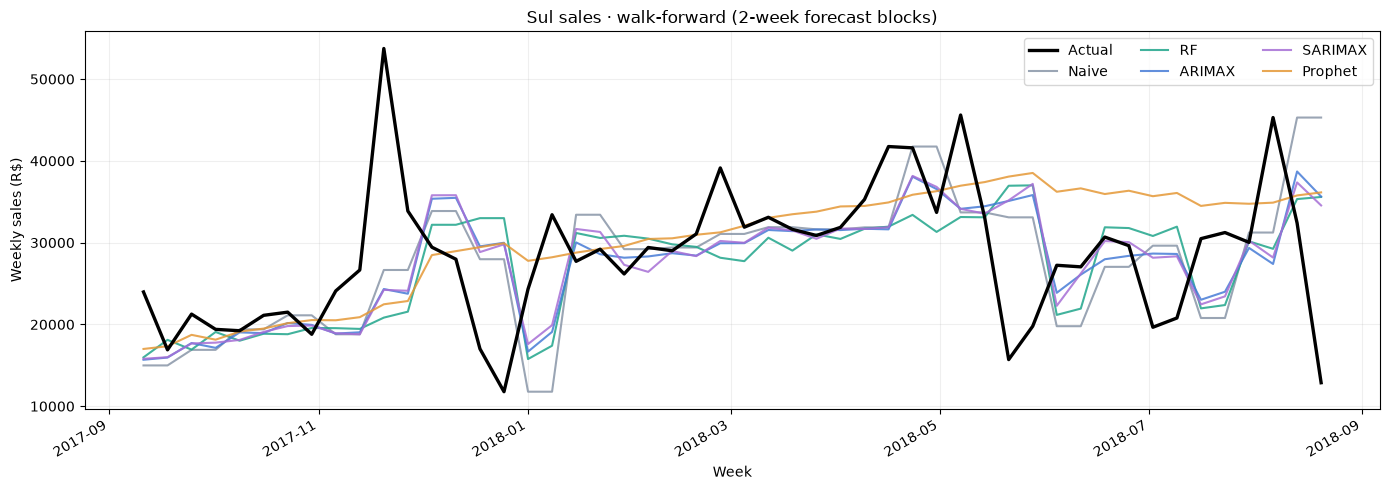

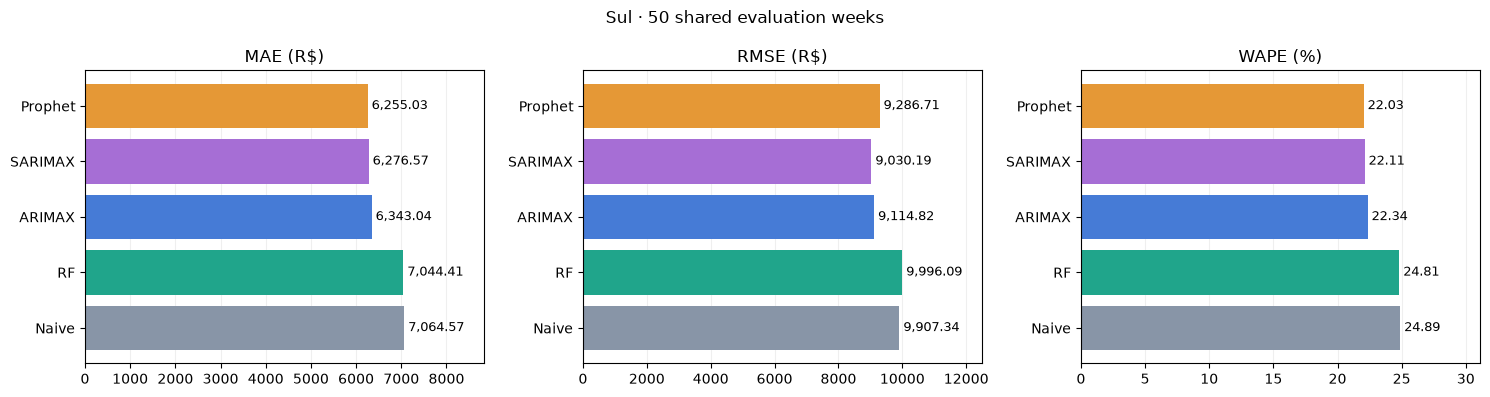

In [10]:
REGION_TO_PLOT = 'Sul'

if REGION_TO_PLOT not in regional_sales.columns:
    raise ValueError(f'Choose one of: {list(regional_sales.columns)}')
regional = predictions.loc[predictions.region.eq(REGION_TO_PLOT)]
wide = regional.pivot(index='week', columns='model', values='prediction').reindex(columns=list(models))
actual = regional_sales[REGION_TO_PLOT].reindex(wide.index)
table = metrics.loc[metrics.Region.eq(REGION_TO_PLOT)].set_index('Model')
colors = {'Naive': '#8895a7', 'RF': '#20a58b', 'ARIMAX': '#467bd6',
          'SARIMAX': '#a66ed5', 'Prophet': '#e59836'}
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(actual.index, actual, color='black', linewidth=2.4, label='Actual', zorder=5)
for name in models:
    ax.plot(wide.index, wide[name], label=name, color=colors[name], alpha=0.85)
ax.set(title=f'{REGION_TO_PLOT} sales · walk-forward ({HORIZON_WEEKS}-week forecast blocks)',
       xlabel='Week', ylabel='Weekly sales (R$)')
ax.legend(ncol=3)
ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ['MAE (R$)', 'RMSE (R$)', 'WAPE (%)']):
    values = table[metric]
    if values.notna().any():
        ax.barh(values.index, values, color=[colors[name] for name in values.index])
        ax.invert_yaxis()
        ax.margins(x=0.25)
        for i, value in enumerate(values):
            if np.isfinite(value):
                ax.text(value, i, f' {value:,.2f}', va='center', fontsize=9)
    else:
        ax.text(0.5, 0.5, 'No defined scores', ha='center', transform=ax.transAxes)
    ax.set_title(metric)
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle(f'{REGION_TO_PLOT} · {int(table["Scored weeks"].iloc[0])} shared evaluation weeks')
plt.tight_layout()
plt.show()

Optional inspection: use `folds` for train/test dates, `predictions` for individual forecasts, and `diagnostics` for model warnings/failures.

Implementation references: [statsmodels SARIMAX](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html), [Prophet seasonality and regressors](https://facebook.github.io/prophet/docs/seasonality%2C_holiday_effects%2C_and_regressors.html), [Prophet non-daily data](https://facebook.github.io/prophet/docs/non-daily_data.html).
